In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot styles.
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

# Load the prepared dataset splits.
PROCESSED_DIR = "../data/processed"

train_df = pd.read_csv(os.path.join(PROCESSED_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROCESSED_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(PROCESSED_DIR, "test.csv"))

print("Data loaded successfully!")

Data loaded successfully!


In [5]:
# Build a summary table for the dataset splits.
summary_data = {
    "Split": ["Train", "Validation", "Test", "TOTAL"],
    "Total Emails": [len(train_df), len(val_df), len(test_df), len(train_df) + len(val_df) + len(test_df)],
    "Legitimate (0)": [
        (train_df['label'] == 0).sum(),
        (val_df['label'] == 0).sum(),
        (test_df['label'] == 0).sum(),
        (train_df['label'] == 0).sum() + (val_df['label'] == 0).sum() + (test_df['label'] == 0).sum()
    ],
    "Phishing (1)": [
        (train_df['label'] == 1).sum(),
        (val_df['label'] == 1).sum(),
        (test_df['label'] == 1).sum(),
        (train_df['label'] == 1).sum() + (val_df['label'] == 1).sum() + (test_df['label'] == 1).sum()
    ],
    "Phishing Ratio (%)": [
        f"{(train_df['label'] == 1).mean() * 100:.2f}%",
        f"{(val_df['label'] == 1).mean() * 100:.2f}%",
        f"{(test_df['label'] == 1).mean() * 100:.2f}%",
        f"{((train_df['label'] == 1).sum() + (val_df['label'] == 1).sum() + (test_df['label'] == 1).sum()) / (len(train_df) + len(val_df) + len(test_df)) * 100:.2f}%"
    ]
}

summary_df = pd.DataFrame(summary_data)
# Display the summary table.
summary_df.style.hide(axis="index").set_caption("Dataset split summary")

Split,Total Emails,Legitimate (0),Phishing (1),Phishing Ratio (%)
Train,91114,50557,40557,44.51%
Validation,19525,10834,8691,44.51%
Test,19525,10834,8691,44.51%
TOTAL,130164,72225,57939,44.51%


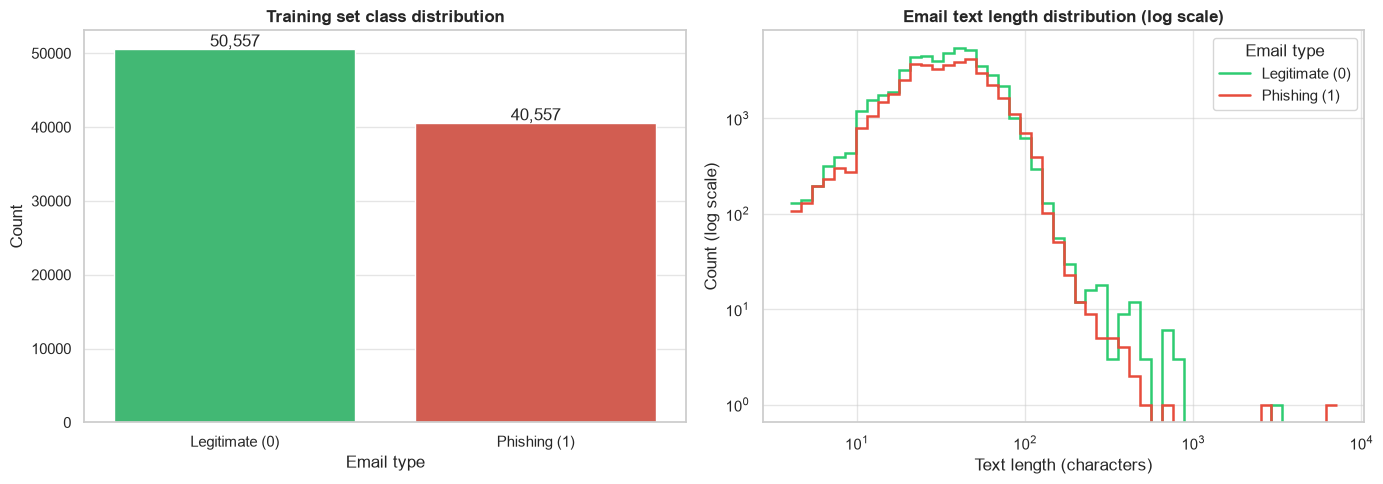

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Class distribution in the training split.
sns.countplot(
    x='label',
    hue='label',
    data=train_df,
    ax=axes[0],
    palette=['#2ecc71', '#e74c3c'],
    legend=False
)
axes[0].set_title("Training set class distribution", fontsize=12, fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Legitimate (0)", "Phishing (1)"])
axes[0].set_xlabel("Email type")
axes[0].set_ylabel("Count")

# Annotate each bar with its count.
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Plot 2: Text length distribution with logarithmically spaced bins.
# Draw unfilled steps without a zero baseline, which is undefined on a log axis.
import numpy as np

plot_data = train_df.assign(text_len=train_df['full_text'].fillna('').str.len())
plot_data = plot_data.loc[plot_data['text_len'] > 0]
if plot_data.empty:
    axes[1].text(0.5, 0.5, "No non-empty text available", ha="center",
                 va="center", transform=axes[1].transAxes)
else:
    min_length = plot_data['text_len'].min()
    max_length = max(plot_data['text_len'].max(), min_length + 1)
    bin_edges = np.geomspace(min_length, max_length, num=51)
    for label, name, color in [(0, "Legitimate (0)", "#2ecc71"),
                               (1, "Phishing (1)", "#e74c3c")]:
        lengths = plot_data.loc[plot_data['label'] == label, 'text_len']
        counts, _ = np.histogram(lengths, bins=bin_edges)
        axes[1].stairs(counts, bin_edges, baseline=None, label=name,
                       color=color, linewidth=1.8)
    axes[1].set_xscale("log")
    axes[1].set_yscale("log", nonpositive="clip")
    axes[1].legend(title="Email type")

axes[1].set_title("Email text length distribution (log scale)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Text length (characters)")
axes[1].set_ylabel("Count (log scale)")

plt.tight_layout()
plt.show()